**Persiapan**

In [ ]:
! pip install tabulate

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tabulate import tabulate

# **Infinite Well Potential-1D**

**Definisikan Potensial $V(x)$**

In [ ]:
def potensial(x):
  return 0

**Hitung $\psi$ dengan Numerov Equation**

In [ ]:
def calculate_psi(x_max, nx, energi, potential):
  # Persiapan step
  dx  = (2 * x_max) / nx
  h2  = dx ** 2
  h12 = h2 / 12

  # Sediakan kumpulan nilai psi di tiap x
  p = []
  x = []
  p.append(0)
  p.append(0.001)
  x.append(-x_max)
  x.append(-x_max + dx)

  # Loop di tiap titik x
  for n in range(0, nx-1):
    f0 = 2 * (potential(-x_max + n*dx) - energi)
    q0 = (1 - f0 * h12) * p[n]
    f1 = 2 * (potential(-x_max + (n+1)*dx) - energi)
    q1 = (1 - f1 * h12) * p[n+1]
    f2 = 2 * (potential(-x_max + (n+2)*dx) - energi)
    q2 = (f0 * h2 * p[n+1]) + (2 * q1) - q0
    u2 = (1 - f2 * h12)

    # Hitung psi selanjutnya
    pn = q2 / u2
    p.append(pn)
    n = n + 1
    x.append(-x_max + (n + 1) * dx)
  return p, x

**Bisection & False Position Method**

In [ ]:
def bisection(energy, dE, x_max, nx, potential):
  # Siapkan dua data untuk biseksi
  E2 = energy
  E1 = energy - dE

  # Siapkan error
  error_value = 1e-12
  iterasi = []

  while True:
    psi_1, x = calculate_psi(x_max, nx, E1, potential)
    psi_2, x = calculate_psi(x_max, nx, E2, potential)

    # Pilih salah satu metode mencari akar
    # E_mid = (E1 + E2) / 2 # Bisection Ori
    E_mid = E1 - ((psi_1[-1] * (E2 - E1))/(psi_2[-1] - psi_1[-1])) # False Method Position

    psi_mid, x = calculate_psi(x_max, nx, E_mid, potential)
    value = psi_mid[-1]
    print(f'Eigen = {E_mid}')
    if abs(value) > error_value:
      if psi_1[-1] * psi_mid[-1] < 0:
        E2 = E_mid
      else:
        E1 = E_mid
    else:
      break
  return E_mid

**Menghitung $E_n$**

In [ ]:
def Eigen(energi_initial, x_max, nx, potensial):
  energi = energi_initial
  dE = 0.1
  psi_error = 1e-12
  p, x = calculate_psi(x_max, nx, energi, potensial)

  while abs(p[-1]) > psi_error:
    if p[-1] > psi_error:
      energi = energi + dE
      p, x = calculate_psi(x_max, nx, energi, potensial)
      if p[-1] < psi_error:
        energi = bisection(energi, dE, x_max, nx, potensial)
        break
      else:
        None
    elif p[-1] < psi_error:
      energi = energi + dE
      p, x = calculate_psi(x_max, nx, energi, potensial)
      if p[-1] > psi_error:
        energi = bisection(energi, dE, x_max, nx, potensial)
        break
      else:
        None
  return energi

**Plot fungsi Gelombang $\psi(x)$**

Masukan banyak state yang ingin dicari: 6
Masukan banyak titik tinjauan: 5000
Lebar potensial dari 0: 2
Eigen = 0.31055998012597624
Eigen = 0.30846846215076906
Eigen = 0.3084260140449447
Eigen = 0.3084251552669288
Eigen = 0.30842513789129394
Eigen = 0.3084251375415754
Eigen = 0.3084251375350187
Eigen = 0.3084251375347872
Eigen = 0.30842513753463857
E1 numerik  = 0.30842513753463857
E1 analitik = 0.30842513753404244
Error Absolut  = 5.961342530724778e-13
Error Relatif  = 1.9328329001934204e-10 %


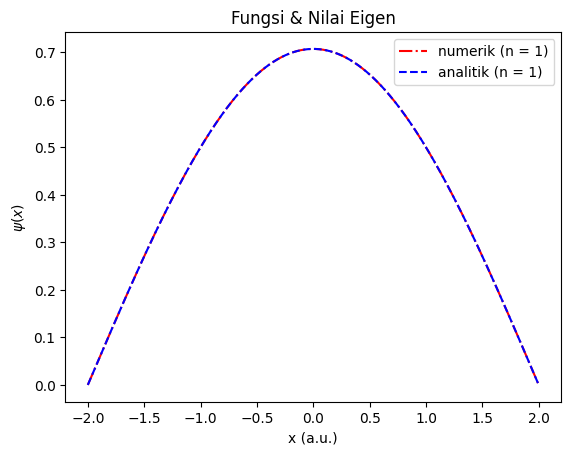

Eigen = 1.2345819121946868
Eigen = 1.2337085338329945
Eigen = 1.2337006223464575
Eigen = 1.2337005507900254
Eigen = 1.233700550140066
Eigen = 1.233700550135813
E2 numerik  = 1.233700550135813
E2 analitik = 1.2337005501361697
Error Absolut  = 3.568256801145253e-13
Error Relatif  = 2.8923200210548712e-11 %


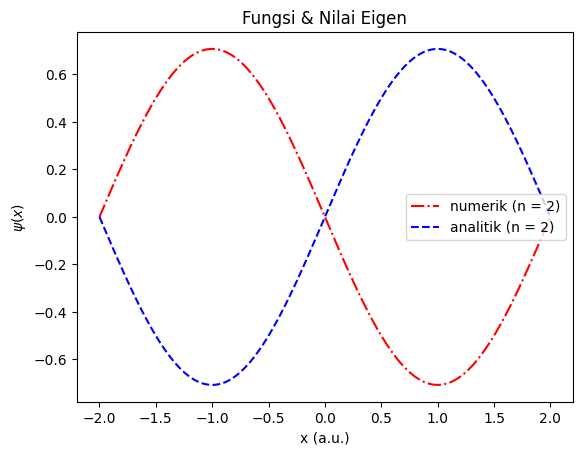

Eigen = 2.7764519559559098
Eigen = 2.7758313708030906
Eigen = 2.775826279865441
Eigen = 2.775826238151366
Eigen = 2.7758262378103193
Eigen = 2.7758262378029004
E3 numerik  = 2.7758262378029004
E3 analitik = 2.775826237806382
Error Absolut  = 3.481659405224491e-12
Error Relatif  = 1.2542785848064823e-10 %


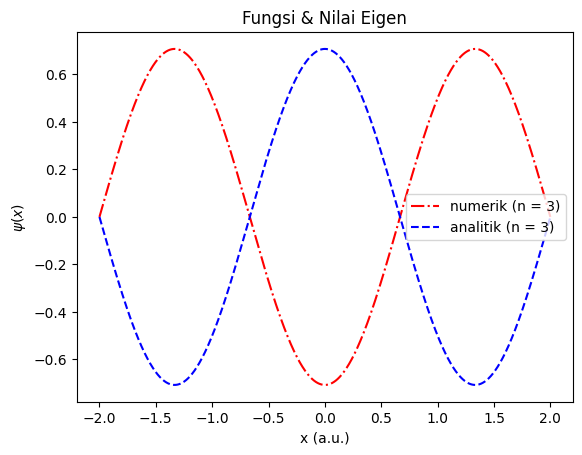

Eigen = 4.935183198313176
Eigen = 4.9348047943048945
Eigen = 4.934802218189519
Eigen = 4.9348022006662
Eigen = 4.934802200546741
Eigen = 4.934802200540288
E4 numerik  = 4.934802200540288
E4 analitik = 4.934802200544679
Error Absolut  = 4.391154106997419e-12
Error Relatif  = 8.898338633537825e-11 %


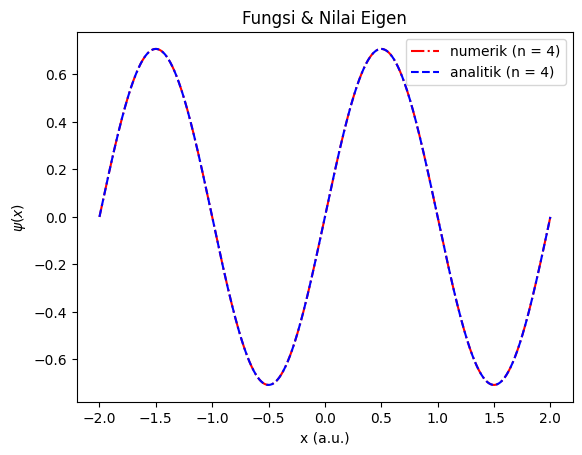

Eigen = 7.7108349618508365
Eigen = 7.710629607605382
Eigen = 7.710628444965394
Eigen = 7.710628438388813
Eigen = 7.710628438348569
E5 numerik  = 7.710628438348569
E5 analitik = 7.710628438351061
Error Absolut  = 2.4922286456785514e-12
Error Relatif  = 3.232199120479888e-11 %


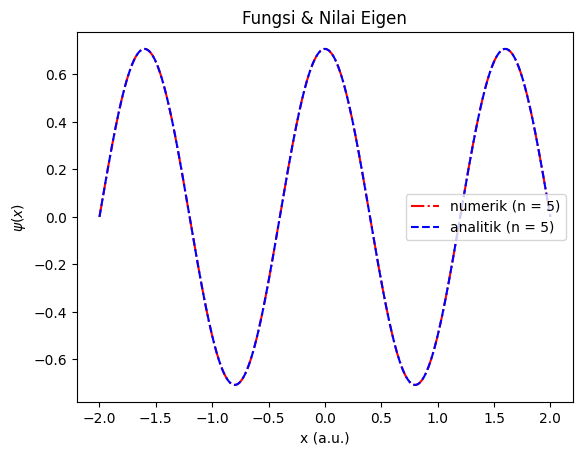

Eigen = 11.103390503776772
Eigen = 11.103305359228267
Eigen = 11.103304953161961
Eigen = 11.103304951224628
Eigen = 11.103304951217204
E6 numerik  = 11.103304951217204
E6 analitik = 11.103304951225528
Error Absolut  = 8.324008149429574e-12
Error Relatif  = 7.496874296432623e-11 %


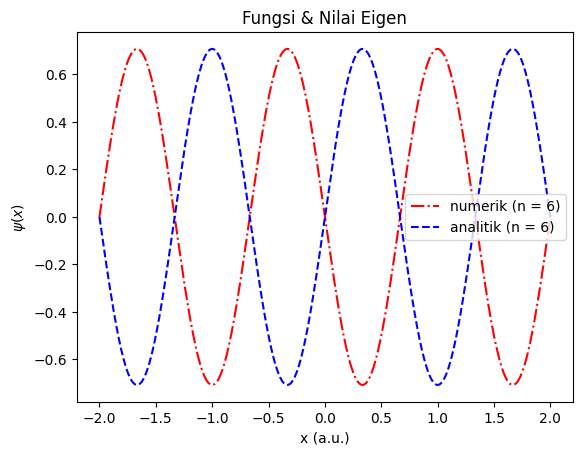


Data Hasil Perhitungan:

+----+---------+-----------------------+--------------------+----------------------+---------------------+
|    |   State |   Energi Numerik (Ha) |   Eigen Value (Ha) |   Error Absolut (Ha) |   Error Relatif (%) |
+====+=========+=======================+====================+======================+=====================+
|  0 |       1 |              0.308425 |           0.308425 |          5.96134e-13 |         1.93283e-10 |
+----+---------+-----------------------+--------------------+----------------------+---------------------+
|  1 |       2 |              1.2337   |           1.2337   |          3.56826e-13 |         2.89232e-11 |
+----+---------+-----------------------+--------------------+----------------------+---------------------+
|  2 |       3 |              2.77583  |           2.77583  |          3.48166e-12 |         1.25428e-10 |
+----+---------+-----------------------+--------------------+----------------------+---------------------+
|  3 |     

In [ ]:
def analitik(state, nx, x_max):
  X = np.linspace(-x_max, x_max, nx)
  if state % 2 == 1:
    y = ((2 / (2 * x_max)) ** 0.5) * np.cos(state * np.pi * X / (2 * x_max))
  elif state % 2 == 0:
    y = np.sqrt(2 / (2 * x_max)) * np.sin(state * np.pi * X / (2 * x_max))
  E = ((state ** 2) * (np.pi ** 2)) / (2 * (2 * x_max)**2)
  return X, y, E

n     = int(input("Masukan banyak state yang ingin dicari: "))
nx    = int(input("Masukan banyak titik tinjauan: "))
x_max = float(input("Lebar potensial dari 0: "))

energi_awal = 0
data_dict = {"State": [], "Energi Numerik (Ha)": [], "Eigen Value (Ha)": [], "Error Absolut (Ha)": [], "Error Relatif (%)": []}

for i in range(0, n):
  energi = Eigen(energi_awal, x_max, nx, potensial)
  X, y, E = analitik(i+1, nx, x_max)
  print(f'E{i+1} numerik  = {energi}')
  p, x = calculate_psi(x_max, nx, energi, potensial)

  print(f'E{i+1} analitik = {E}')
  error_abs = abs(energi - E)
  error_rel = (error_abs / E) * 100
  print(f'Error Absolut  = {error_abs}')
  print(f'Error Relatif  = {error_rel} %')

  # Simpan data ke dictionary untuk DataFrame
  data_dict["State"].append(i + 1)
  data_dict["Energi Numerik (Ha)"].append(energi)
  data_dict["Eigen Value (Ha)"].append(E)
  data_dict["Error Absolut (Ha)"].append(error_abs)
  data_dict["Error Relatif (%)"].append(error_rel)

  #Normalisasi fungsi gelombang dengan metode integral Trapezoid
  sigma_f = 0
  for j in range(nx):
    p_kuadrat = p[j]*p[j]
    sigma_f = sigma_f + p_kuadrat
    j = i + 1

  integral = (2*x_max/nx/2)*(2*sigma_f - p[0]*p[0] - p[-1]*p[-1])  #Rumus Luas Trapesium
  norm = 1/(integral**(1/2))
  p = [psi*norm for psi in p]
  energi_awal = energi + 0.01
  i = i+1

  plt.title('Fungsi & Nilai Eigen')
  plt.plot(x, p, linestyle = '-.', color = 'red', label = f'numerik (n = {i})')
  plt.plot(X, y, linestyle = '--', color = 'blue', label = f'analitik (n = {i})')
  plt.xlabel('x (a.u.)')  # Label x lebih besar dan tebal
  plt.ylabel('$\psi(x)$')
  plt.legend()
  plt.show()

# Buat DataFrame dari data_dict
df = pd.DataFrame(data_dict)

# Cetak tabel hasil akhir dengan tabulate
print("\nData Hasil Perhitungan:\n")
print(tabulate(df, headers="keys", tablefmt="grid"))

# Simpan ke file CSV
df.to_csv("hasil_perhitungan.csv", index=False)
print("\nData berhasil disimpan ke 'hasil_perhitungan.csv'.")

# **Potential Well dengan Gangguan**

 **Definisikan Potensial**

In [ ]:
def potensial(x):
  if -x_max <= x <= 0:
    return 2
  else:
    return 0

**Hitung $\psi(x)$ dengan *Numerov Equation***

In [ ]:
def calculate_psi(x_max, nx, energi, potensial):
  # Persiapan step
  dx  = (2 * x_max) / nx
  h2  = dx ** 2
  h12 = h2 / 12

  # Sediakan kumpulan nilai psi di tiap x
  p = []
  x = []
  p.append(0)
  p.append(0.0001)
  x.append(-x_max)
  x.append(-x_max + dx)

  # Loop di tiap titik x
  for n in range(0, nx-1):
    f0 = 2 * (potensial(-x_max + n*dx) - energi)
    q0 = (1 - f0 * h12) * p[n]
    f1 = 2 * (potensial(-x_max + (n+1)*dx) - energi)
    q1 = (1 - f1 * h12) * p[n+1]
    f2 = 2 * (potensial(-x_max + (n+2)*dx) - energi)
    q2 = (f0 * h2 * p[n+1]) + (2 * q1) - q0
    u2 = (1 - f2 * h12)

    # Hitung psi selanjutnya
    pn = q2 / u2
    p.append(pn)
    n = n + 1
    x.append(-x_max + (n + 1) * dx)
  return p, x

**Bisection and False Position Method**

In [ ]:
def bisection(energy, dE, x_max, nx, potensial):
  # Siapkan dua data untuk biseksi
  E2 = energy
  E1 = energy - dE

  # Siapkan error
  error_value = 1e-12
  iterasi = []
  i = 0

  while True:
    psi_1, x = calculate_psi(x_max, nx, E1, potensial)
    psi_2, x = calculate_psi(x_max, nx, E2, potensial)

    # Pilih salah satu metode mencari akar
    # E_mid = (E1 + E2) / 2 # Bisection Ori
    E_mid = E1 - ((psi_1[-1] * (E2 - E1))/(psi_2[-1] - psi_1[-1])) # False Method Position

    psi_mid, x = calculate_psi(x_max, nx, E_mid, potensial)
    value = psi_mid[-1]
    print(f'Eigen = {E_mid}')

    if i == 1000:
      break

    if abs(value) < error_value:
      break

    if psi_1[-1] * psi_mid[-1] < 0:
      E2 = E_mid
    else:
      E1 = E_mid

    i += 1

  return E_mid

**Menghitung *Eigen value* $E_{n}$**

In [ ]:
def Eigen(energi_initial, x_max, nx, potensial):
  energi = energi_initial
  dE = 0.1
  psi_error = 1e-12
  p, x = calculate_psi(x_max, nx, energi, potensial)

  while abs(p[-1]) > psi_error:
    if p[-1] > psi_error:
      energi = energi + dE
      p, x = calculate_psi(x_max, nx, energi, potensial)
      if p[-1] == psi_error:
        break
      if p[-1] < psi_error:
        energi = bisection(energi, dE, x_max, nx, potensial)
        break
      else:
        None
    elif p[-1] < psi_error:
      energi = energi + dE
      p, x = calculate_psi(x_max, nx, energi, potensial)
      if p[-1] == psi_error:
        break
      if p[-1] > psi_error:
        energi = bisection(energi, dE, x_max, nx, potensial)
        break
      else:
        None
  return energi

**Plot fungsi Gelombang $\psi(x)$**

Masukan banyak state yang ingin dicari: 6
Masukan banyak titik tinjauan: 5000
Lebar potensial dari 0: 2
Eigen = 0.7708294587067567
Eigen = 0.7674241027756675
Eigen = 0.7670386211840209
Eigen = 0.7669951404385661
Eigen = 0.7669902379646564
Eigen = 0.7669896852313485
Eigen = 0.7669896229164584
Eigen = 0.7669896158888013
Eigen = 0.7669896150985193
Eigen = 0.7669896150093125
Eigen = 0.766989614998023
Eigen = 0.7669896149970401
E1 numerik  = 0.7669896149970401
E1 approksimasi = 1.3084251375340425
Error Absolut  = 0.5414355225370024
Error Relatif  = 41.38070318317432 %


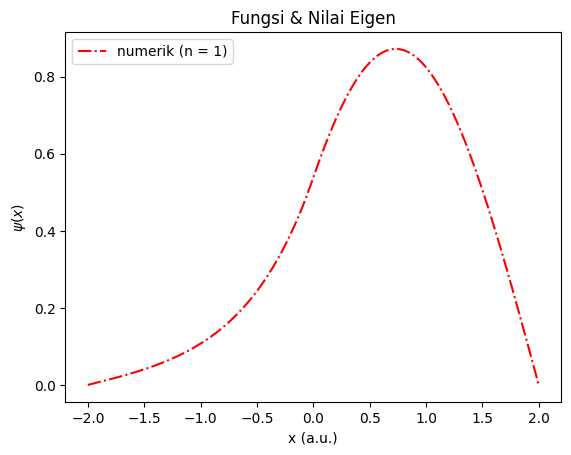

Eigen = 2.5224204663988803
Eigen = 2.5193672476322844
Eigen = 2.519206400412094
Eigen = 2.519197954762623
Eigen = 2.5191975113798164
Eigen = 2.5191974881040746
Eigen = 2.5191974868828746
Eigen = 2.519197486816725
E2 numerik  = 2.519197486816725
E2 approksimasi = 2.2337005501361697
Error Absolut  = 0.2854969366805551
Error Relatif  = 12.781343348066542 %


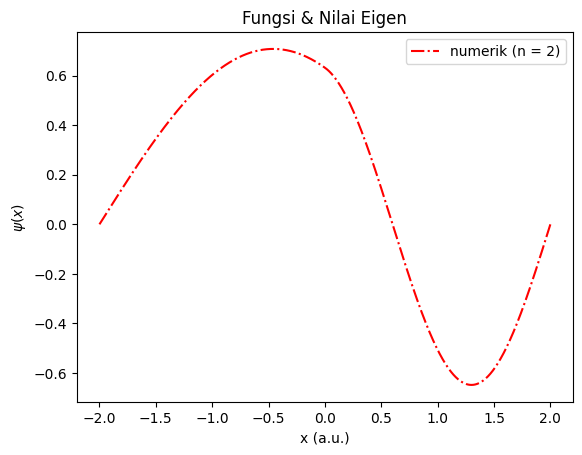

Eigen = 3.761897048197407
Eigen = 3.7615185258392745
Eigen = 3.7615168254711286
Eigen = 3.761516817845975
Eigen = 3.761516817808458
E3 numerik  = 3.761516817808458
E3 approksimasi = 3.775826237806382
Error Absolut  = 0.0143094199979239
Error Relatif  = 0.37897453687479943 %


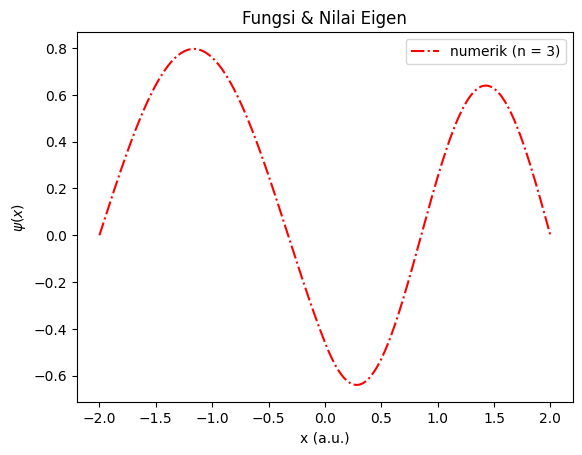

Eigen = 6.060419492351115
Eigen = 6.060223916153998
Eigen = 6.060220521452315
Eigen = 6.0602204625459395
Eigen = 6.060220461524251
Eigen = 6.060220461504969
E4 numerik  = 6.060220461504969
E4 approksimasi = 5.934802200544679
Error Absolut  = 0.12541826096028963
Error Relatif  = 2.1132677505036157 %


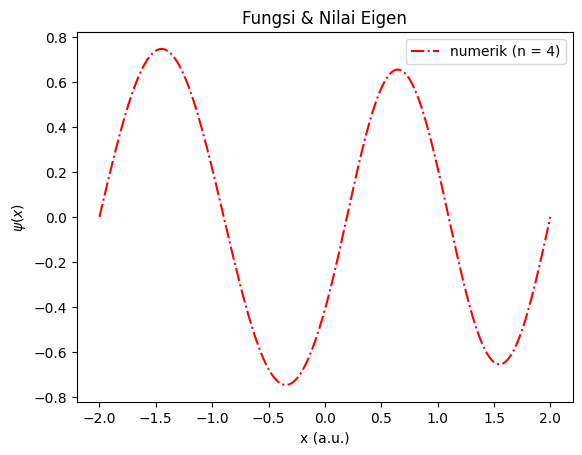

Eigen = 8.689689759779151
Eigen = 8.689563568945793
Eigen = 8.689563405610775
Eigen = 8.68956340539626
E5 numerik  = 8.68956340539626
E5 approksimasi = 8.710628438351062
Error Absolut  = 0.021065032954801666
Error Relatif  = 0.24183137995023143 %


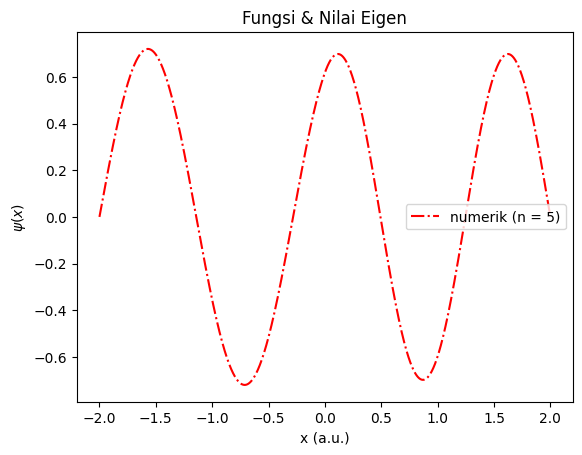

Eigen = 12.16577943200579
Eigen = 12.165604023682416
Eigen = 12.165603159801663
Eigen = 12.165603155548448
E6 numerik  = 12.165603155548448
E6 approksimasi = 12.103304951225528
Error Absolut  = 0.06229820432291966
Error Relatif  = 0.5147206037852629 %


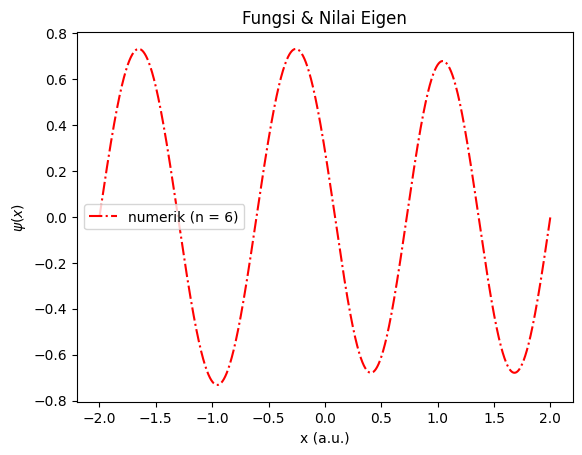


Data Hasil Perhitungan:

+----+---------+-----------------------+---------------------------+----------------------+---------------------+
|    |   State |   Energi Numerik (Ha) |   Eigen Approksimasi (Ha) |   Error Absolut (Ha) |   Error Relatif (%) |
+====+=========+=======================+===========================+======================+=====================+
|  0 |       1 |               0.76699 |                   1.30843 |            0.541436  |           41.3807   |
+----+---------+-----------------------+---------------------------+----------------------+---------------------+
|  1 |       2 |               2.5192  |                   2.2337  |            0.285497  |           12.7813   |
+----+---------+-----------------------+---------------------------+----------------------+---------------------+
|  2 |       3 |               3.76152 |                   3.77583 |            0.0143094 |            0.378975 |
+----+---------+-----------------------+----------------------

In [ ]:
def analitik(state, nx, x_max):
  X = np.linspace(-x_max, x_max, nx)
  if state % 2 == 1:
    y = ((2 / (2 * x_max)) ** 0.5) * np.cos(state * np.pi * X / (2 * x_max))
  elif state % 2 == 0:
    y = np.sqrt(2 / (2 * x_max)) * np.sin(state * np.pi * X / (2 * x_max))
  E = ((state ** 2) * (np.pi ** 2)) / (2 * (2 * x_max)**2) + ((2 / (2 * x_max)) * (x_max))
  return X, y, E

n     = int(input("Masukan banyak state yang ingin dicari: "))
nx    = int(input("Masukan banyak titik tinjauan: "))
x_max = float(input("Lebar potensial dari 0: "))

energi_awal = 0
data_dict = {"State": [], "Energi Numerik (Ha)": [], "Eigen Approksimasi (Ha)": [], "Error Absolut (Ha)": [], "Error Relatif (%)": []}

for i in range(0, n):
  energi = Eigen(energi_awal, x_max, nx, potensial)
  X, y, E = analitik(i+1, nx, x_max)
  print(f'E{i+1} numerik  = {energi}')
  p, x = calculate_psi(x_max, nx, energi, potensial)

  print(f'E{i+1} approksimasi = {E}')
  error_abs = abs(energi - E)
  error_rel = (error_abs / E) * 100
  print(f'Error Absolut  = {error_abs}')
  print(f'Error Relatif  = {error_rel} %')

  # Simpan data ke dictionary untuk DataFrame
  data_dict["State"].append(i + 1)
  data_dict["Energi Numerik (Ha)"].append(energi)
  data_dict["Eigen Approksimasi (Ha)"].append(E)
  data_dict["Error Absolut (Ha)"].append(error_abs)
  data_dict["Error Relatif (%)"].append(error_rel)

  #Normalisasi fungsi gelombang dengan metode integral Trapezoid
  sigma_f = 0
  for j in range(nx):
    p_kuadrat = p[j]*p[j]
    sigma_f = sigma_f + p_kuadrat
    j = j + 1

  integral = (2*x_max/nx/2)*(2*sigma_f - p[0]*p[0] - p[-1]*p[1])  #Rumus Luas Trapesium
  norm = 1/(integral**(1/2))
  p = [psi*norm for psi in p]
  energi_awal = energi + 0.01
  i = i+1

  plt.title('Fungsi & Nilai Eigen')
  plt.plot(x, p, linestyle = '-.', color = 'red', label = f'numerik (n = {i})')
  # plt.plot(X, y, linestyle = '--', color = 'blue', label = f'analitik (n = {i})')
  plt.xlabel('x (a.u.)')  # Label x lebih besar dan tebal
  plt.ylabel('$\psi(x)$')
  plt.legend()
  plt.show()

# Buat DataFrame dari data_dict
df = pd.DataFrame(data_dict)

# Cetak tabel hasil akhir dengan tabulate
print("\nData Hasil Perhitungan:\n")
print(tabulate(df, headers="keys", tablefmt="grid"))

# Simpan ke file CSV
df.to_csv("hasil_perhitungan.csv", index=False)
print("\nData berhasil disimpan ke 'hasil_perhitungan.csv'.")